# India AI Lawyer — 4-Agent Self-RAG Workflow

A compact, problem-focused legal-information assistant for everyday Indian legal problems.

## Four agents

1. **Case Intake & Structuring Agent** — turns an informal narrative into facts, timeline, evidence, goals, urgency, jurisdiction, and missing details.
2. **Self-RAG Knowledge Agent** — retrieves relevant passages from the Legal Aid Handbook and decides whether they are relevant and sufficient. It routes to web research whenever information is missing, outdated, jurisdiction-specific, or needs primary legal authority.
3. **Web Research Agent** — plans targeted searches, runs Tavily multi-query search, deduplicates results, and labels source types/authority signals. This preserves the Self-RAG → web-search fallback.
4. **Legal Guidance & Safety Agent** — explains practical options and next steps, identifies evidence to preserve, and drafts notices/complaints/replies when requested. It performs a final safety/citation check in the same response-generation call.

This keeps the workflow to **four LangGraph agents** without separate planner, source-review, reasoning, and audit nodes. Source labels are heuristic signals, not legal verification.

> **Scope:** This notebook provides general legal information, not legal representation. It must not invent provisions, deadlines, fees, case citations, or claim that a law is in force without evidence. State-specific law and current legal status require official-source verification.


## 1. Setup

Required packages (install in your active Python environment if needed):

```bash
python3 -m pip install -U langchain langchain-community langchain-groq langchain-huggingface langchain-text-splitters langchain-tavily langgraph faiss-cpu sentence-transformers pypdf python-dotenv tqdm
```

Set `GROQ_API_KEY` and `TAVILY_API_KEY` in `/home/eclipse/ai_lawyer/.env`.

The notebook reuses the existing FAISS index at `/home/eclipse/ai_lawyer/vector_store/legal_aid_faiss`. It will generate embeddings only if the index files are absent.


In [9]:
import os
import json
from datetime import date
from typing import List, Dict, Any, Literal, TypedDict

from pydantic import BaseModel, Field
from dotenv import load_dotenv

from langchain_community.document_loaders import PyPDFLoader
from langchain_community.vectorstores import FAISS
from langchain_groq import ChatGroq
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_core.documents import Document
from langchain_core.prompts import ChatPromptTemplate
from langchain_tavily import TavilySearch

from langgraph.graph import StateGraph, START, END

load_dotenv("/home/eclipse/ai_lawyer/.env")

if not os.getenv("GROQ_API_KEY"):
    raise EnvironmentError("GROQ_API_KEY is missing from /home/eclipse/ai_lawyer/.env")
if not os.getenv("TAVILY_API_KEY"):
    raise EnvironmentError("TAVILY_API_KEY is missing from /home/eclipse/ai_lawyer/.env")

HANDBOOK_PATH = "/home/eclipse/ai_lawyer/Legal-Aid-Handbook.pdf"
VECTOR_STORE_PATH = "/home/eclipse/ai_lawyer/vector_store/legal_aid_faiss"
TODAY = date.today().isoformat()

if not os.path.isfile(HANDBOOK_PATH):
    raise FileNotFoundError(f"Handbook not found: {HANDBOOK_PATH}")

# Groq chat model
llm = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0,
    max_tokens=1800,
    api_key=os.getenv("GROQ_API_KEY"),
)

# Hugging Face embedding model (cached locally after first download)
embeddings = HuggingFaceEmbeddings(
    model_name="BAAI/bge-m3",
    model_kwargs={"device": "cpu"},
    encode_kwargs={"normalize_embeddings": True},
)

# Load the persistent FAISS index; build it only on the first run.
index_file = os.path.join(VECTOR_STORE_PATH, "index.faiss")
metadata_file = os.path.join(VECTOR_STORE_PATH, "index.pkl")

if os.path.exists(index_file) and os.path.exists(metadata_file):
    print("Loading existing Legal Aid Handbook FAISS index...")
    vector_store = FAISS.load_local(
        VECTOR_STORE_PATH,
        embeddings,
        allow_dangerous_deserialization=True,  # Only load an index you created/trust.
    )
    print("Existing FAISS index loaded.")
else:
    print("No saved FAISS index found. Building it once from the handbook...")
    pages = PyPDFLoader(HANDBOOK_PATH).load()
    splitter = RecursiveCharacterTextSplitter(
        chunk_size=900,
        chunk_overlap=180,
        separators=["\n\n", "\n", ". ", " ", ""],
    )
    chunks = splitter.split_documents(pages)
    print(f"Pages: {len(pages)} | Chunks: {len(chunks)}")
    if not chunks:
        raise ValueError("No text chunks were extracted from the handbook PDF.")
    vector_store = FAISS.from_documents(chunks, embeddings)
    os.makedirs(VECTOR_STORE_PATH, exist_ok=True)
    vector_store.save_local(VECTOR_STORE_PATH)
    print("FAISS index generated and saved.")

retriever = vector_store.as_retriever(search_kwargs={"k": 4})

# Tavily multi-query search. TavilySearch reads TAVILY_API_KEY from the environment.
tavily = TavilySearch(
    max_results=5,
    search_depth="advanced",
    include_raw_content=True,
)

print("Initialization complete:", TODAY)


Loading weights: 100%|██████████| 391/391 [00:00<00:00, 29516.09it/s]


Loading existing Legal Aid Handbook FAISS index...
Existing FAISS index loaded.
Initialization complete: 2026-11-07


## 2. Shared graph state

In [10]:
class LegalState(TypedDict, total=False):
    question: str

    # Agent 1: case intake
    intake: Dict[str, Any]
    retrieval_query: str

    # Agent 2: Self-RAG
    handbook_docs: List[Document]
    handbook_context: str
    handbook_assessment: Dict[str, Any]
    need_web_research: bool

    # Agent 3: web research
    search_queries: List[str]
    web_docs: List[Document]
    web_context: str

    # Agent 4: final response
    evidence_context: str
    answer: str


## 3. Agent 1 — Case Intake & Structuring

In [11]:
# AGENT 1 — CASE INTAKE & STRUCTURING

class IntakeResult(BaseModel):
    is_legal_query: bool
    language: str
    country: str
    state_or_ut: str
    legal_domain: str
    issues: List[str]
    facts: List[str]
    timeline: List[str]
    evidence_mentioned: List[str]
    user_goal: str
    urgency_or_risk: List[str]
    missing_information: List[str]

intake_prompt = ChatPromptTemplate.from_messages([
    ("system",
     "You are the CASE INTAKE AND STRUCTURING AGENT for an India-focused legal-information assistant. "
     "Convert the user's everyday-language narrative into a concise structured case brief. "
     "Do not answer the legal question or give legal conclusions. "
     "Record only facts explicitly supplied; never invent dates, facts, identity, legal status, or jurisdiction. "
     "If the state/UT is unknown, write 'not specified'. Identify urgent safety concerns without inventing deadlines. "
     "Capture the user's goal and any document they want drafted. Respond in the user's language for the language field."),
    ("human", "User's message:\n{question}")
])

intake_chain = intake_prompt | llm.with_structured_output(IntakeResult)

def intake_agent(state: LegalState):
    result = intake_chain.invoke({"question": state["question"]})
    intake = result.model_dump()
    retrieval_query = " ".join([
        state["question"],
        intake["legal_domain"],
        " ".join(intake["issues"]),
        intake["state_or_ut"] if intake["state_or_ut"] != "not specified" else "",
    ]).strip()
    return {"intake": intake, "retrieval_query": retrieval_query}


## 4. Agent 2 — Self-RAG Knowledge Retrieval & Gap Assessment

In [12]:
# AGENT 2 — SELF-RAG KNOWLEDGE RETRIEVAL & GAP ASSESSMENT
# Retrieval and sufficiency assessment are one graph agent.
# Web research is triggered when evidence is missing, irrelevant, insufficient, or potentially outdated.

class HandbookAssessment(BaseModel):
    relevant: bool = Field(description="Whether the retrieved handbook passages are relevant to the actual issue.")
    sufficient: bool = Field(description="Whether they safely answer the material question, including jurisdiction and procedure.")
    potentially_outdated: bool = Field(description="Whether current law, amendments, commencement, deadlines, fees, or procedure need verification.")
    covered_points: List[str]
    missing_points: List[str]
    web_search_needed: bool

selfrag_prompt = ChatPromptTemplate.from_messages([
    ("system",
     "You are the SELF-RAG KNOWLEDGE AGENT. Assess the retrieved Legal Aid Handbook passages against the user's actual problem. "
     "The handbook is secondary plain-language material, not a complete or necessarily current statement of law. "
     "Set sufficient=true only when the passages answer the material question with adequate jurisdictional and procedural detail. "
     "Set web_search_needed=true for missing details, state-specific law, current legal status, amendments, commencement, official procedure, "
     "deadlines, fees, remedies, or when primary legal authority is required. "
     "If passages are empty, irrelevant, or merely mention a topic, web_search_needed=true. "
     "Do not fill gaps from legal memory. List the exact gaps."),
    ("human",
     "Current date: {today}\nUser question: {question}\nCase brief: {intake}\n"
     "Retrieved handbook passages:\n{handbook_context}")
])

selfrag_chain = selfrag_prompt | llm.with_structured_output(HandbookAssessment)

def self_rag_agent(state: LegalState):
    docs = retriever.invoke(state.get("retrieval_query", state["question"]))
    formatted = []
    for doc in docs:
        page = doc.metadata.get("page")
        page_label = f"page {int(page) + 1}" if isinstance(page, int) else "page not identified"
        formatted.append(f"[LEGAL AID HANDBOOK | {page_label}]\n{doc.page_content}")

    handbook_context = "\n\n---\n\n".join(formatted)
    assessment = selfrag_chain.invoke({
        "today": TODAY,
        "question": state["question"],
        "intake": json.dumps(state.get("intake", {}), ensure_ascii=False),
        "handbook_context": handbook_context or "No handbook passages retrieved.",
    }).model_dump()

    need_web = (
        assessment["web_search_needed"]
        or not assessment["relevant"]
        or not assessment["sufficient"]
        or assessment["potentially_outdated"]
    )

    print("Self-RAG decision:", "WEB SEARCH REQUIRED" if need_web else "HANDBOOK SUFFICIENT")
    return {
        "handbook_docs": docs,
        "handbook_context": handbook_context,
        "handbook_assessment": assessment,
        "need_web_research": need_web,
    }


## 5. Agent 3 — Targeted Web Research & Source Signals

In [13]:
# AGENT 3 — TARGETED WEB RESEARCH
# The planner creates complementary queries; Tavily runs each query.
# Source authority labels below are URL-based signals only, not proof of legal validity.

class SearchPlan(BaseModel):
    queries: List[str] = Field(description="Five distinct targeted search queries. Do not answer the legal question.")

search_plan_prompt = ChatPromptTemplate.from_messages([
    ("system",
     "You are the WEB RESEARCH PLANNER for an India-focused legal assistant. "
     "Create five complementary search queries that fill the Self-RAG gaps. Seek: "
     "(1) applicable central Act and exact provisions from India Code/official source; "
     "(2) relevant state/UT Acts, rules, notifications, amendments; "
     "(3) current procedure, authority, forms, fees, complaint/appeal route from official sources; "
     "(4) relevant Supreme Court or jurisdictionally relevant High Court judgments; "
     "(5) official legal-aid or government guidance. "
     "For employment, investigate commencement and applicable rules; enactment alone does not prove commencement. "
     "For tenancy, search the relevant state rent/tenancy law; do not assume the Model Tenancy Act applies. "
     "Prefer official domains such as indiacode.nic.in, egazette.nic.in, gov.in, nic.in, nalsa.gov.in, sci.gov.in, and official High Court sites. "
     "Include the state/UT if known. Do not answer the legal question."),
    ("human",
     "Current date: {today}\nQuestion: {question}\nCase brief: {intake}\n"
     "Handbook gaps: {gaps}")
])

search_plan_chain = search_plan_prompt | llm.with_structured_output(SearchPlan)

def authority_signal(url: str) -> str:
    u = (url or "").lower()
    if any(x in u for x in ["indiacode.nic.in", "egazette.nic.in"]):
        return "potential_primary_government_source — verify the actual Act/rule/notification"
    if any(x in u for x in ["sci.gov.in", "main.sci.gov.in", "highcourt", "hc.nic.in", "ecourts.gov.in"]):
        return "potential_court_source — verify judgment, bench, date, jurisdiction, and later treatment"
    if any(x in u for x in [".gov.in", ".nic.in", "nalsa.gov.in"]):
        return "potential_official_guidance — guidance is not necessarily legislation"
    return "secondary_or_unverified_source — do not treat as primary law"

def normalize_tavily_results(raw):
    if isinstance(raw, dict):
        raw = raw.get("results", [])
    return raw if isinstance(raw, list) else []

def web_research_agent(state: LegalState):
    plan = search_plan_chain.invoke({
        "today": TODAY,
        "question": state["question"],
        "intake": json.dumps(state.get("intake", {}), ensure_ascii=False),
        "gaps": json.dumps(state.get("handbook_assessment", {}).get("missing_points", []), ensure_ascii=False),
    })

    queries = list(dict.fromkeys(q.strip() for q in plan.queries if q and q.strip()))
    if len(queries) < 5:
        domain = state.get("intake", {}).get("legal_domain", "Indian law")
        jurisdiction = state.get("intake", {}).get("state_or_ut", "India")
        fallbacks = [
            f"{domain} applicable Act rules official India Code {jurisdiction}",
            f"{domain} state law notification official government {jurisdiction}",
            f"{domain} complaint procedure competent authority official {jurisdiction}",
            f"{domain} Supreme Court High Court judgment official India",
            f"{domain} legal aid government guidance India",
        ]
        queries = list(dict.fromkeys(queries + fallbacks))
    queries = queries[:5]

    all_docs, seen_urls = [], set()
    for query in queries:
        try:
            results = normalize_tavily_results(tavily.invoke({"query": query}))
        except Exception as exc:
            print(f"Tavily search failed for {query!r}: {exc}")
            continue

        for item in results:
            url = item.get("url", "") or ""
            if url and url in seen_urls:
                continue
            if url:
                seen_urls.add(url)

            title = item.get("title", "Untitled source")
            content = item.get("raw_content") or item.get("content") or item.get("snippet") or ""
            if not content.strip():
                content = "No substantive page content returned; the source must be opened and checked."

            # Limit each result to keep the Groq prompt within the TPM budget.
            content = content[:1800]
            all_docs.append(Document(
                page_content=(
                    f"SEARCH QUERY: {query}\nTITLE: {title}\nURL: {url}\n"
                    f"AUTHORITY SIGNAL: {authority_signal(url)}\nCONTENT:\n{content}"
                ),
                metadata={
                    "source": "web",
                    "url": url,
                    "title": title,
                    "search_query": query,
                    "authority_signal": authority_signal(url),
                },
            ))

    # Keep the strongest compact set for the final response; original URLs are retained.
    selected_docs = all_docs[:8]
    web_context_parts = []
    for i, doc in enumerate(selected_docs, 1):
        web_context_parts.append(f"[WEB SOURCE {i}]\n{doc.page_content}")
    web_context = "\n\n".join(web_context_parts)

    print(f"Web research completed: {len(queries)} queries, {len(all_docs)} unique results, {len(selected_docs)} passed to the final agent.")
    return {
        "search_queries": queries,
        "web_docs": selected_docs,
        "web_context": web_context,
    }


## 6. Agent 4 — Legal Guidance, Drafting & Built-in Safety Check

In [14]:
# AGENT 4 — LEGAL GUIDANCE, DOCUMENT DRAFTING & SAFETY CHECK

def build_evidence_context(state: LegalState) -> str:
    parts = []
    handbook = state.get("handbook_context", "")
    if handbook:
        parts.append("=== LEGAL AID HANDBOOK (SECONDARY EXPLANATORY SOURCE) ===\n" + handbook[:4500])

    web = state.get("web_context", "")
    if web:
        parts.append("=== TAVILY WEB RESULTS (NOT YET INDEPENDENTLY VERIFIED) ===\n" + web[:9000])

    if not parts:
        return "No supporting evidence was retrieved."
    return "\n\n".join(parts)

legal_response_prompt = ChatPromptTemplate.from_messages([
    ("system",
     """
     You are a friendly, empathetic, approachable and knowledgeable AI Legal Assistant
     designed to help ordinary people understand their legal problems in India.

     ==============================
     CONVERSATIONAL PERSONALITY
     ==============================

     1. Always begin your response with a natural, warm greeting or acknowledgement.

     Examples:
     - "Hi! Don't worry, I'm here to help you understand your options."
     - "Hello! I understand your concern. Let's work through this step by step."
     - "Hey! I can certainly help you understand what you can do in this situation."
     - "I understand how frustrating this situation can be. Let's see what options are available to you."

     2. Do not mechanically repeat the same greeting in every response.
        Vary your opening according to the user's situation.

     3. Acknowledge the user's emotions when appropriate.
        If someone is facing harassment, financial loss, threats, or distress,
        respond with empathy rather than immediately presenting legal provisions.

     4. Avoid unnecessarily complicated legal terminology.
        Explain legal concepts as if you are speaking to an ordinary person
        who has little or no legal knowledge.

     5. Maintain a conversational, reassuring and respectful tone throughout.
        Do not sound like a court judgment, legal textbook or government notification.

     6. Do not provide false reassurance or promise a favourable legal outcome.
        In urgent or dangerous situations, prioritise practical safety guidance
        over generic reassuring statements.

     ==============================
     LEGAL REASONING & ACCURACY
     ==============================

     1. Help ordinary people understand practical legal options under Indian law.

     2. Use the user's stated facts and supplied evidence only.
        Never invent facts or assume missing information.

     3. Treat the Legal Aid Handbook as a secondary explanatory source.
        Web search results and URL authority labels are leads, not verified legal authority.

     4. Prefer actual primary legal text, Gazette notifications and relevant judgments.

     5. Never invent:
        - Act names or section numbers
        - Case names or citations
        - Legal deadlines or limitation periods
        - Fees, forms or authorities
        - Legal procedures or remedies

     6. If the supplied evidence does not support a legal detail,
        clearly explain that it needs verification.

     7. Distinguish central law from state/UT law.
        If state law may change the answer and the state is unknown,
        explain the uncertainty and ask the user to specify the state.

     8. For employment law, flag uncertainty about Labour Code commencement
        and applicable rules.

     9. For tenancy, do not assume the Model Tenancy Act applies.

     ==============================
     HELP THE USER TAKE ACTION
     ==============================

     Explain:
     - What the user's legal problem appears to be.
     - What legal options may be available.
     - What practical steps the user can take.
     - Which documents and evidence they should preserve.
     - Which authority or institution they may approach.
     - When consulting a qualified advocate is advisable.

     If the user requests a legal notice, complaint, reply, application
     or another document, provide a usable draft with placeholders
     for missing information.

     If the user wants to practise arguments or prepare for a hearing,
     offer role-play or sample talking points, not predictions of outcomes.

     For immediate danger, violence, arrest or urgent safety issues,
     prioritise emergency assistance and a qualified local advocate.

     ==============================
     RESPONSE STYLE
     ==============================

     Structure your response naturally:

     1. A warm conversational opening.
     2. A simple explanation of the user's situation.
     3. Relevant legal position, with citations where supported.
     4. Practical options and step-by-step actions.
     5. Documents or evidence to preserve.
     6. Important uncertainties or missing information.
     7. A friendly closing offering further assistance.

     Do not force every heading into every response.
     Keep straightforward questions concise and provide detailed guidance
     when the situation requires it.

     If the user needs to provide additional information,
     ask only the most important questions instead of overwhelming them.

     Respond in the same language as the user.

     ==============================
     CITATIONS & SAFETY
     ==============================

     Cite legal claims inline using the supplied source title and URL,
     or the Legal Aid Handbook page number.

     Never fabricate citations.

     Before responding, silently audit your answer:
     - Remove unsupported legal claims.
     - Qualify uncertain jurisdiction and currentness.
     - Preserve source URLs.
     - Distinguish legal requirements from general suggestions.

     Include a concise disclaimer that this is general legal information
     and not a substitute for advice from a qualified advocate.
     """
    ),
    ("human",
     "Current date: {today}\n\n"
     "USER'S ORIGINAL MESSAGE:\n{question}\n\n"
     "STRUCTURED CASE BRIEF:\n{intake}\n\n"
     "SELF-RAG HANDBOOK ASSESSMENT:\n{assessment}\n\n"
     "EVIDENCE:\n{evidence_context}\n\n"
     "If the handbook was sufficient and web research was skipped, "
     "do not imply that a web search was performed.")
])

def legal_response_agent(state: LegalState):
    evidence_context = build_evidence_context(state)
    response = llm.invoke(legal_response_prompt.format_messages(
        today=TODAY,
        question=state["question"],
        intake=json.dumps(state.get("intake", {}), ensure_ascii=False),
        assessment=json.dumps(state.get("handbook_assessment", {}), ensure_ascii=False),
        evidence_context=evidence_context,
    ))
    return {
        "evidence_context": evidence_context,
        "answer": response.content,
    }


## 7. Build the four-agent graph

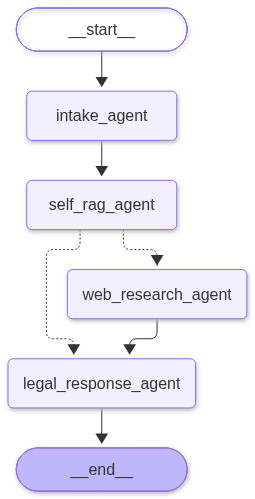

In [15]:
# FOUR-NODE LANGGRAPH WORKFLOW

def route_after_self_rag(state: LegalState) -> Literal["web_research_agent", "legal_response_agent"]:
    return "web_research_agent" if state.get("need_web_research", True) else "legal_response_agent"

graph = StateGraph(LegalState)

graph.add_node("intake_agent", intake_agent)                 # Agent 1
graph.add_node("self_rag_agent", self_rag_agent)              # Agent 2
graph.add_node("web_research_agent", web_research_agent)      # Agent 3
graph.add_node("legal_response_agent", legal_response_agent)  # Agent 4

graph.add_edge(START, "intake_agent")
graph.add_edge("intake_agent", "self_rag_agent")
graph.add_conditional_edges(
    "self_rag_agent",
    route_after_self_rag,
    {
        "web_research_agent": "web_research_agent",
        "legal_response_agent": "legal_response_agent",
    },
)
graph.add_edge("web_research_agent", "legal_response_agent")
graph.add_edge("legal_response_agent", END)

app = graph.compile()
app


## 8. Ask a legal question

In [16]:
# Replace the example with a real user query.
user_question = (
    "My landlord in Dehradun is refusing to return my security deposit after I vacated "
    "the flat. I have a rent agreement and payment proofs. What can I do?"
)

result = app.invoke({
    "question": user_question,
    "handbook_docs": [],
    "handbook_context": "",
    "web_docs": [],
    "web_context": "",
    "answer": "",
})

print(result["answer"])


Self-RAG decision: WEB SEARCH REQUIRED
Web research completed: 5 queries, 24 unique results, 8 passed to the final agent.
**Hello! I’m sorry you’re having to chase your deposit – let’s see how you can get it back.**  

---

### 1. What’s happening here?  
You rented a flat in Dehradun, paid a security deposit, vacated the premises, and now the landlord is refusing to return that deposit. You have a written rent agreement and proof of the deposit payment.

---

### 2. Legal position in Uttarakhand  

| Point | What the law says (Uttarakhand) |
|-------|---------------------------------|
| **Applicable statute** | *Uttarakhand Tenancy Act, 2021* (the newer tenancy law for the state). The Act contains a specific provision on security deposits – **Chapter III, Section 11 – “Security deposit”**【WEB SOURCE 1】. |
| **Refund obligation** | The landlord must **refund the security deposit (or the balance after lawful deductions) within a reasonable time after the tenancy ends**, usually within *

## 9. Inspect the agent outputs

In [ ]:
print("CASE INTAKE")
print(json.dumps(result.get("intake", {}), indent=2, ensure_ascii=False))

print("\nSELF-RAG ASSESSMENT")
print(json.dumps(result.get("handbook_assessment", {}), indent=2, ensure_ascii=False))

print("\nWEB SEARCH QUERIES")
for query in result.get("search_queries", []):
    print("-", query)

print("\nWEB SOURCES PASSED TO THE FINAL AGENT")
for doc in result.get("web_docs", []):
    print({
        "title": doc.metadata.get("title"),
        "url": doc.metadata.get("url"),
        "authority_signal": doc.metadata.get("authority_signal"),
    })


## 10. What changed and why

| Previous workflow | New workflow |
|---|---|
| Intake agent | **Agent 1: Case Intake & Structuring** |
| Handbook retrieval + gap analysis as separate nodes | **Agent 2: Self-RAG Knowledge Agent** (combined) |
| Web planner + Tavily search + per-result LLM source verification | **Agent 3: Web Research Agent** (planner + same multi-query Tavily search; lightweight URL authority signals replace repeated per-result LLM calls) |
| Legal reasoning + separate response audit | **Agent 4: Legal Guidance & Safety Agent** (one response-generation call with an explicit self-audit instruction) |

### Why this is more efficient

- Four graph nodes instead of eight.
- No separate LLM call for every web result.
- No second LLM call just to audit the final answer.
- Self-RAG still decides whether the handbook is sufficient.
- If the handbook is insufficient or potentially outdated, the graph still performs five targeted Tavily searches.
- The final agent receives a compact set of retrieved evidence to reduce TPM errors.

### Important limitations

- URL-based authority labels are only heuristics. A `.gov.in` URL does not prove that a page contains current legislation; a court URL does not prove a judgment remains good law.
- Tavily results must be opened and checked against the actual Act, rules, Gazette notification, or judgment before relying on them in a high-stakes matter.
- The Legal Aid Handbook is a 2022 secondary source and may be outdated or incomplete.
- The notebook accepts text. Voice support requires a speech-to-text component before the intake agent.
- For criminal exposure, eviction proceedings, arrest, violence, major financial loss, limitation-sensitive matters, or court filings, escalate to a qualified local advocate or the relevant legal services authority.
- Do not automatically send notices or complaints. Let the user review and confirm any generated document before use.
